# Прогноз накопленных и недельных Fälle и Lückentage к отчётной дате

Укажите анкерный год, Sachverhalt, ось дат и Stichtag. Итоговая таблица покажет последнее известное накопленное значение, прогнозируемую прибавку и прогноз накопленного итога для обеих величин.

- **IPL** — накопленный итог по версиям случаев, доступным к указанной дате IPL. Снимки между собой не суммируются. Исправления могут уменьшать итог.
- **ELAD** — накопленный итог по дате первой загрузки (erstes Ladedatum) на основе версий, доступных на дату среза.
- Случай определяется по BWPKKD, Ankerbeginn, YBWRIQBPS и YBWRBPF. Два последних поля могут быть пустыми. Как и в приложении, сначала отбираются записи по пересечению анкерного года и Sachverhalt, затем выбирается версия случая.

Период моделирования начинается с 2024 года. Более ранние случаи, входящие в когорту, сохраняются в начальном накопленном итоге.

In [1]:
from functools import lru_cache
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import curve_fit
from scipy.special import expit

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pack/config.py").is_file())
sys.path.insert(0, str(root))
from pack.config import ANALYSIS_START_YEAR, DB_PATH
from pack.data_access import database_connection
from pack.services.quality_service import parse_source_date

ANCHOR_YEAR = None        # None выбирает последний анкерный год
SACHVERHALT = "all"       # Например, "01b"
DATE_BASIS = "ELAD"       # "IPL" или "ELAD"
AS_OF_DATE = None         # None выбирает последнюю доступную дату на выбранной оси
TARGET_DATE = None       # Например, "2027-02-15". None задаёт горизонт 13 недель
HORIZON_WEEKS = 13
RECENT_WEEKS = 12
MAX_BACKTEST_WINDOWS = 7
HANA_COVERAGE_CONFIRMED = False

if DATE_BASIS not in {"IPL", "ELAD"}:
    raise ValueError("DATE_BASIS должен быть IPL или ELAD.")
analysis_start = pd.Timestamp(ANALYSIS_START_YEAR, 1, 1)
metrics = ["Fälle", "Lückentage"]
key = ["case_id", "anchor_start", "iqbps", "bpf"]

## 1. Проверки источника и выбор версии случая

На каждом историческом срезе допускаются только записи с IPL не позднее даты среза. Записи с пустым ключом, неверными датами, обратным периодом или некорректным числом дней исключаются и подсчитываются. 31.12.9999 считается открытым периодом.

Если в одном IPL у случая есть конфликтующие версии, используем воспроизводимое правило: более ранняя дата первой загрузки, затем меньшее число дней. Это технический выбор для эксперимента. Число неоднозначных ключей выводится отдельно. Полнота выгрузки подтверждается сверкой с SAP HANA.

In [2]:
with database_connection(read_only=True, path=DB_PATH) as connection:
    raw = connection.execute('''
        SELECT TRIM(CAST("/B99/S_BWPKKD" AS VARCHAR)) AS case_id,
               CASE WHEN TRIM("/BIC/YBWRIQBPS") = '' THEN NULL ELSE "/BIC/YBWRIQBPS" END AS iqbps,
               CASE WHEN TRIM("/BIC/YBWRBPF") = '' THEN NULL ELSE "/BIC/YBWRBPF" END AS bpf,
               CAST("/BIC/YBWRSV" AS VARCHAR) AS category,
               CAST("/BIC/YBWRAVON" AS VARCHAR) AS anchor_start,
               CAST("/BIC/YBWRABIS" AS VARCHAR) AS anchor_end,
               CAST("/BIC/YBWRELAD" AS VARCHAR) AS elad,
               CAST("/BIC/YBWRIPL" AS VARCHAR) AS ipl,
               TRY_CAST("/BIC/YBWRFTAGE" AS DOUBLE) AS days
        FROM raw_bestand
        WHERE "/BIC/YBWRSEL" = '4.15.1' AND "/BIC/YBWRIQIQ" = 'RSA'
    ''').df()
if raw.empty:
    raise ValueError("Нет данных RSA / 4.15.1. Загрузите выгрузку SAP HANA.")

for name in ["anchor_start", "anchor_end", "elad", "ipl"]:
    parsed = {value: parse_source_date(value) for value in raw[name].dropna().unique()}
    raw[name] = raw[name].map(parsed)
bad_dates = raw[["anchor_start", "anchor_end", "elad", "ipl"]].isna().any(axis=1)
checks = pd.DataFrame({
    "Пустой ключ": raw["case_id"].fillna("").eq(""),
    "Нераспознанная дата": bad_dates,
    "Конец периода раньше начала": ~bad_dates & raw["anchor_end"].lt(raw["anchor_start"]),
    "Первая загрузка раньше начала": ~bad_dates & raw["elad"].lt(raw["anchor_start"]),
    "IPL раньше первой загрузки": ~bad_dates & raw["ipl"].lt(raw["elad"]),
    "Некорректные Lückentage": ~np.isfinite(raw["days"]) | raw["days"].lt(0) | raw["days"].mod(1).ne(0),
})
data = raw.loc[~checks.any(axis=1)].drop_duplicates().copy()
if data.empty:
    raise ValueError("После проверок не осталось пригодных записей.")
for name in ["elad", "ipl"]:
    data[name] = pd.to_datetime(data[name])
version_key = key + ["ipl"]
conflicts = data.loc[data.duplicated(version_key, keep=False), version_key].drop_duplicates()
display(checks.sum().to_frame("Строк"))
display(pd.Series({
    "Строк в выгрузке": len(raw),
    "Строк, исключённых по проверкам": int(checks.any(axis=1).sum()),
    "Ключей с разными версиями в одном IPL": len(conflicts),
    "Полнота SAP HANA подтверждена": HANA_COVERAGE_CONFIRMED,
}).to_frame("Источник"))

data = data.sort_values(["ipl", "elad", "days"], ascending=[True, False, False])
last_ipl = data["ipl"].max()
last_elad = data["elad"].max()
latest_anchor_year = max(ANALYSIS_START_YEAR, max(d.year for d in data["anchor_start"]))
anchor_year = latest_anchor_year if ANCHOR_YEAR is None else int(ANCHOR_YEAR)
latest_axis_date = last_ipl if DATE_BASIS == "IPL" else last_elad
origin = pd.Timestamp(AS_OF_DATE).normalize() if AS_OF_DATE else latest_axis_date
target = pd.Timestamp(TARGET_DATE).normalize() if TARGET_DATE else origin + pd.Timedelta(weeks=HORIZON_WEEKS)
if not analysis_start <= origin <= latest_axis_date or target <= origin:
    raise ValueError("Дата среза должна лежать в наблюдаемом периоде с 2024 года, а Stichtag — позже неё.")

@lru_cache(maxsize=None)
def cohort(year):
    start = pd.Timestamp(year, 1, 1).date()
    end = pd.Timestamp(year, 12, 31).date()
    selected = data["anchor_start"].le(end) & data["anchor_end"].ge(start)
    if SACHVERHALT != "all":
        selected &= data["category"].eq(SACHVERHALT)
    return data.loc[selected]

def snapshot(year, cutoff):
    rows = cohort(year)
    return rows.loc[rows["ipl"].le(cutoff)].drop_duplicates(key, keep="last")

@lru_cache(maxsize=None)
def actual(year, cutoff):
    rows = snapshot(year, cutoff)
    return len(rows), rows["days"].sum()

@lru_cache(maxsize=None)
def history(year, cutoff):
    # Сетка привязана к дате среза, включая саму дату среза.
    periods = (cutoff - analysis_start).days // 7 + 1
    dates = pd.date_range(end=cutoff, periods=periods, freq="7D")
    if DATE_BASIS == "IPL":
        return pd.DataFrame([actual(year, day) for day in dates], index=dates, columns=metrics)
    rows = snapshot(year, cutoff)
    daily = rows.groupby("elad").agg(Fälle=("case_id", "size"), Lückentage=("days", "sum"))
    return daily.cumsum().reindex(dates, method="ffill").fillna(0)

if cohort(anchor_year).empty:
    raise ValueError("В выбранной когорте нет записей.")

,Строк
Пустой ключ,0
Нераспознанная дата,0
Конец периода раньше начала,0
Первая загрузка раньше начала,0
IPL раньше первой загрузки,0
Некорректные Lückentage,0


,Источник
Строк в выгрузке,549794
"Строк, исключённых по проверкам",0
Ключей с разными версиями в одном IPL,0
Полнота SAP HANA подтверждена,False


## 2. Накопленные кривые и прогноз

Сравниваем сохранение текущего итога, продолжение среднего темпа последних 12 недель и логистическую S-кривую. S-кривая добавляет к известному итогу только прогнозируемый прирост. Она оценивается отдельно для Fälle и Lückentage и применяется только при достаточной истории роста. Сравнение когорт выравнивает их по дате конца анкерного года. Один случай может входить в несколько лет.

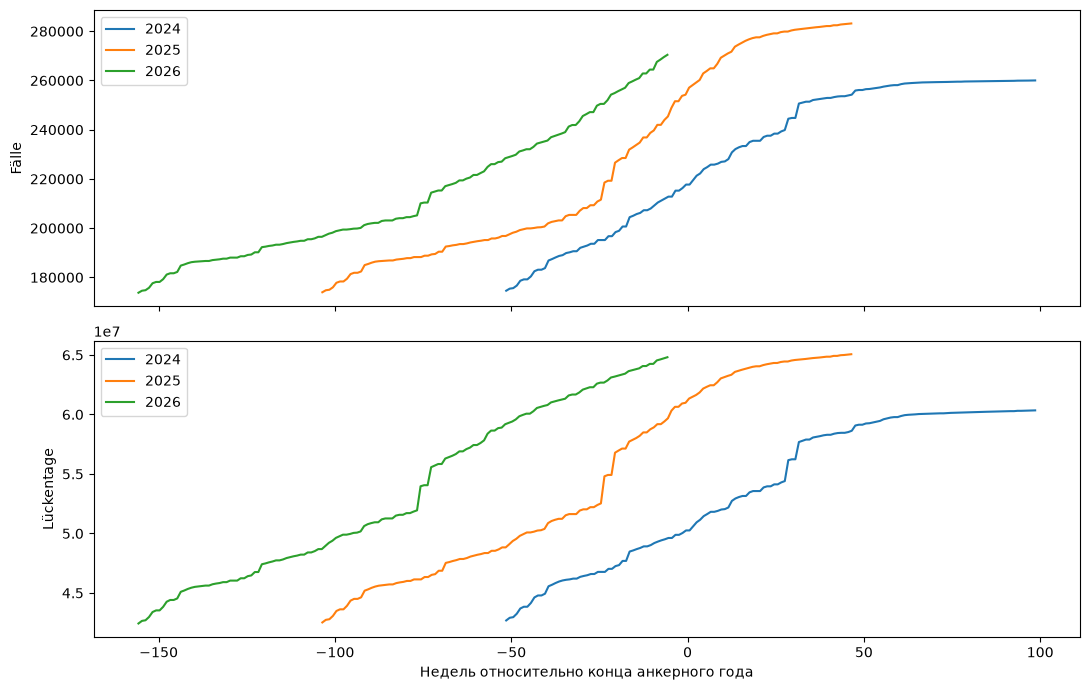

In [3]:
def logistic(x, ceiling, rate, midpoint):
    return ceiling * expit(rate * (x - midpoint))

def predict(series, cutoff, deadline):
    horizon = (deadline - cutoff).days / 7
    values = series.to_numpy(dtype=float)
    current = values[-1]
    predictions = {"Текущий итог": current}
    if len(values) < 2:
        return predictions
    changes = np.diff(values)[-RECENT_WEEKS:]
    predictions["Недавний темп"] = max(0, current + changes.mean() * horizon)

    # Подгоняем накопленный прирост с начала видимого периода.
    x = (series.index - series.index[0]).days.to_numpy() / 7
    scale = values[-1] - values[0]
    if len(values) < 26 or scale <= 0 or (np.diff(values) > 0).sum() < 12:
        return predictions
    y = (values - values[0]) / scale

    def curve(time, ceiling, rate, midpoint):
        return logistic(time, ceiling, rate, midpoint) - logistic(0, ceiling, rate, midpoint)

    try:
        params, _ = curve_fit(
            curve, x, y, p0=[2, 0.08, x[-1] / 2],
            bounds=([1, 0.001, -x[-1]], [20, 2, 2 * x[-1]]),
            maxfev=4000,
        )
        # Достижение границы потолка означает, что насыщение не определилось.
        if params[0] < 19.99:
            growth = scale * (curve(x[-1] + horizon, *params) - curve(x[-1], *params))
            predictions["S-кривая"] = current + max(0, growth)
    except (RuntimeError, ValueError):
        pass
    return predictions

current_history = history(anchor_year, origin)
cohort_years = sorted(set(range(ANALYSIS_START_YEAR, latest_anchor_year + 1)) | {anchor_year})
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for year in cohort_years:
    if cohort(year).empty:
        continue
    curve = history(year, origin)
    age = (curve.index - pd.Timestamp(year, 12, 31)).days / 7
    for ax, metric in zip(axes, metrics):
        ax.plot(age, curve[metric], label=str(year))
for ax, metric in zip(axes, metrics):
    ax.set_ylabel(metric)
    ax.legend()
axes[-1].set_xlabel("Недель относительно конца анкерного года")
fig.tight_layout()
plt.show()

## 3. Проверка на исторических срезах и результат к Stichtag

Исторические окна имеют ту же длину в днях, что и выбранный прогноз. На каждой дате модель видит только версии до этой даты IPL. Факт — накопленный итог по версиям, доступным на целевую дату. Результаты моделей сравниваются на одинаковых срезах. Ошибка выражена в случаях или днях, а смещение показывает систематическое завышение или занижение. Для фиксированного начального итога ошибка прогноза накопленного значения равна ошибке прогноза прибавки.

Три общих окна — минимальное условие выбора по ошибке в этом эксперименте. При меньшем числе окон итоговая таблица показывает ориентир по недавнему темпу. Результат остаётся предварительным до сверки полноты выгрузки.

In [4]:
horizon = target - origin
validation = []
for step in range(1, MAX_BACKTEST_WINDOWS + 1):
    old_origin = origin - step * horizon
    old_target = old_origin + horizon
    if old_origin < analysis_start + pd.Timedelta(weeks=25):
        break
    if old_origin < data["ipl"].min() or old_target > latest_axis_date:
        continue
    old_history = history(anchor_year, old_origin)
    for metric, observed in zip(metrics, actual(anchor_year, old_target)):
        for model, estimate in predict(old_history[metric], old_origin, old_target).items():
            validation.append({
                "Показатель": metric, "Модель": model, "Дата среза": old_origin,
                "Целевая дата": old_target, "Факт": observed, "Прогноз": estimate,
                "Ошибка": estimate - observed, "Абсолютная ошибка": abs(estimate - observed),
            })

score = pd.DataFrame()
if validation:
    errors = pd.DataFrame(validation)
    common_scores = []
    for metric, group in errors.groupby("Показатель"):
        counts = group.groupby("Модель")["Дата среза"].nunique()
        eligible = counts[counts.ge(3)].index
        comparable = group.loc[group["Модель"].isin(eligible)]
        shared = comparable.groupby("Дата среза")["Модель"].transform("nunique").eq(len(eligible))
        common_scores.append(comparable.loc[shared])
    comparable = pd.concat(common_scores)
    score = comparable.groupby(["Показатель", "Модель"]).agg(
        Окон=("Ошибка", "size"),
        MAE=("Абсолютная ошибка", "mean"),
        Смещение=("Ошибка", "mean"),
    ).reset_index().sort_values(["Показатель", "MAE"])
    display(errors.round({"Факт": 1, "Прогноз": 1, "Ошибка": 1, "Абсолютная ошибка": 1}))
    display(score.round(1))

result = []
for metric in metrics:
    estimates = predict(current_history[metric], origin, target)
    model = "Недавний темп" if "Недавний темп" in estimates else "Текущий итог"
    checked = score.loc[
        score["Показатель"].eq(metric) & score["Окон"].ge(3) & score["Модель"].isin(estimates)
    ] if not score.empty else score
    if not checked.empty:
        model = checked.iloc[0]["Модель"]
    current = current_history[metric].iloc[-1]
    for candidate, estimate in estimates.items():
        result.append({
            "Показатель": metric, "Модель": candidate, "Выбрана": candidate == model,
            "Накоплено на дату среза": current, "Прогноз прибавки": estimate - current,
            "Накопленный прогноз на Stichtag": estimate,
        })

display(pd.Series({
    "Ankerjahr": anchor_year, "Sachverhalt": SACHVERHALT, "Ось": DATE_BASIS,
    "Дата среза": origin.date(), "Stichtag": target.date(),
    "Последний IPL в выгрузке": last_ipl.date(), "Последний ELAD в выгрузке": last_elad.date(),
}).to_frame("Параметры"))
display(pd.DataFrame(result).round(1))
if not HANA_COVERAGE_CONFIRMED:
    print("Предварительный результат. Полнота выгрузки SAP HANA не подтверждена.")

,Показатель,Модель,Дата среза,Целевая дата,Факт,Прогноз,Ошибка,Абсолютная ошибка
0,Fälle,Текущий итог,2026-08-22,2026-11-21,270428.0,239864.0,-30564.0,30564.0
1,Fälle,Недавний темп,2026-08-22,2026-11-21,270428.0,244844.1,-25583.9,25583.9
2,Fälle,S-кривая,2026-08-22,2026-11-21,270428.0,247309.1,-23118.9,23118.9
3,Lückentage,Текущий итог,2026-08-22,2026-11-21,64807292.0,59541165.0,-5266127.0,5266127.0
4,Lückentage,Недавний темп,2026-08-22,2026-11-21,64807292.0,60173976.8,-4633315.2,4633315.2
5,Lückentage,S-кривая,2026-08-22,2026-11-21,64807292.0,60901455.1,-3905836.9,3905836.9
6,Fälle,Текущий итог,2026-05-23,2026-08-22,239864.0,228958.0,-10906.0,10906.0
7,Fälle,Недавний темп,2026-05-23,2026-08-22,239864.0,232469.1,-7394.9,7394.9
8,Fälle,S-кривая,2026-05-23,2026-08-22,239864.0,235008.2,-4855.8,4855.8
9,Lückentage,Текущий итог,2026-05-23,2026-08-22,59541165.0,57476171.0,-2064994.0,2064994.0


,Показатель,Модель,Окон,MAE,Смещение
0,Fälle,S-кривая,7,7509.7,-7509.7
1,Fälle,Недавний темп,7,7769.8,-7630.2
2,Fälle,Текущий итог,7,10905.0,-10905.0
3,Lückentage,S-кривая,5,2090918.3,-2090918.3
4,Lückentage,Недавний темп,5,2208337.0,-2184511.6
5,Lückentage,Текущий итог,5,2799013.6,-2799013.6


,Параметры
Ankerjahr,2026
Sachverhalt,all
Ось,ELAD
Дата среза,2026-11-21
Stichtag,2027-02-20
Последний IPL в выгрузке,2026-11-21
Последний ELAD в выгрузке,2026-11-21


,Показатель,Модель,Выбрана,Накоплено на дату среза,Прогноз прибавки,Накопленный прогноз на Stichtag
0,Fälle,Текущий итог,False,270428.0,0.0,270428.0
1,Fälle,Недавний темп,False,270428.0,14501.5,284929.5
2,Fälle,S-кривая,True,270428.0,13173.5,283601.5
3,Lückentage,Текущий итог,False,64807292.0,0.0,64807292.0
4,Lückentage,Недавний темп,False,64807292.0,1497029.1,66304321.1
5,Lückentage,S-кривая,True,64807292.0,1330247.9,66137539.9


Предварительный результат. Полнота выгрузки SAP HANA не подтверждена.


## 4. Некумулятивный прогноз по Erstes Ladedatum к Stichtag

Целевая величина — Fälle и сумма Lückentage для случаев с первым Ladedatum от понедельника по Stichtag включительно. Например, для четверга используются четыре дня. Раздел всегда работает по ELAD, даже если выше выбрана ось IPL.

Исторические прогнозы имеют тот же горизонт в календарных днях, что и выбранный Stichtag. В обучении используются только версии, доступные к дате прогноза, и завершённые недели. Сравниваются среднее и медиана для того же дня недели. Для Lückentage дополнительно проверяется расчёт через среднее число случаев и медиану числа дней на случай по тем же неделям с ненулевым числом случаев.

Факт фиксируется на первом доступном IPL на дату Stichtag или позже неё. Это позволяет учесть случаи, впервые загруженные до Stichtag и опубликованные ближайшим снимком. Таблица показывает задержку публикации. Окна с задержкой больше 7 дней пропускаются. Полнота конкретных исторических недель требует отдельного подтверждения. Нулевые недельные значения учитываются в расчёте.

Результаты дают MAE и смещение по каждому дню недели. Сводный результат ограничен днём недели выбранного Stichtag. Если наблюдений мало, оценка остаётся предварительной.


In [5]:
weekday_names = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
publication_dates = pd.DatetimeIndex(data["ipl"].drop_duplicates()).sort_values()
max_publication_lag = pd.Timedelta(days=7)
min_training_weeks = 4

def week_start(day):
    return day - pd.Timedelta(days=day.weekday())

def interval_totals(day_counts, deadline):
    values = day_counts.loc[week_start(deadline):deadline, metrics]
    return values.sum()

def elad_daily(cutoff):
    rows = snapshot(anchor_year, cutoff)
    return rows.groupby("elad").agg(Fälle=("case_id", "size"), Lückentage=("days", "sum"))

def weekly_candidates(daily, cutoff, deadline):
    publications = publication_dates[publication_dates <= cutoff]
    if publications.empty:
        return {}, 0
    earliest = max(analysis_start, publications[0])
    complete_before = week_start(publications[-1])
    starts = pd.date_range(earliest, complete_before - pd.Timedelta(days=7), freq="W-MON")
    starts = starts[-RECENT_WEEKS:]
    if len(starts) < min_training_weeks:
        return {}, len(starts)
    offset = pd.Timedelta(days=deadline.weekday())
    training = pd.DataFrame([interval_totals(daily, start + offset) for start in starts])
    means = training.mean()
    forecasts = {"Недавнее среднее": means, "Недавняя медиана": training.median()}
    active_weeks = training.loc[training["Fälle"].gt(0)]
    days_per_case = (active_weeks["Lückentage"] / active_weeks["Fälle"]).median() if not active_weeks.empty else 0
    forecasts["Через Fälle"] = pd.Series({"Lückentage": means["Fälle"] * days_per_case})
    return forecasts, len(starts)

weekly_errors = []
skipped_targets = 0
for weekday in range(7):
    latest_deadline = publication_dates[-1]
    latest_deadline -= pd.Timedelta(days=(latest_deadline.weekday() - weekday) % 7)
    for deadline in pd.date_range(end=latest_deadline, periods=MAX_BACKTEST_WINDOWS, freq="7D"):
        cutoff = deadline - (target - origin)
        if cutoff < analysis_start:
            skipped_targets += 1
            continue
        publication = publication_dates[publication_dates.searchsorted(deadline)]
        if publication - deadline > max_publication_lag:
            skipped_targets += 1
            continue
        forecasts, training_weeks = weekly_candidates(elad_daily(cutoff), cutoff, deadline)
        if not forecasts:
            skipped_targets += 1
            continue
        observed = interval_totals(elad_daily(publication), deadline)
        for model, estimates in forecasts.items():
            for metric, estimate in estimates.items():
                fact = observed[metric]
                weekly_errors.append({
                    "Срез IPL": cutoff, "Начало недели": week_start(deadline),
                    "Stichtag": deadline, "День": weekday_names[weekday],
                    "IPL факта": publication, "Задержка IPL, дней": (publication - deadline).days,
                    "Недель обучения": training_weeks, "Показатель": metric, "Модель": model,
                    "Факт": fact, "Прогноз": estimate,
                    "Ошибка": estimate - fact, "Абсолютная ошибка": abs(estimate - fact),
                })

weekly_score = pd.DataFrame()
if weekly_errors:
    weekly_details = pd.DataFrame(weekly_errors)
    weekly_score = weekly_details.groupby(["День", "Показатель", "Модель"], sort=False).agg(
        Окон=("Ошибка", "size"), MAE=("Абсолютная ошибка", "mean"),
        Смещение=("Ошибка", "mean"), Нулевых_фактов=("Факт", lambda values: values.eq(0).sum()),
        Средняя_задержка_IPL=("Задержка IPL, дней", "mean"),
    ).reset_index()
    display(weekly_score.round(1))
    selected_day = weekday_names[target.weekday()]
    display(weekly_details.loc[weekly_details["День"].eq(selected_day)].round({
        "Прогноз": 1, "Ошибка": 1, "Абсолютная ошибка": 1,
    }))
else:
    print("Для исторической проверки недельных значений недостаточно наблюдений.")
print(f"Пропущено исторических Stichtag: {skipped_targets}")

estimates, training_weeks = weekly_candidates(elad_daily(origin), origin, target)
weekly_forecast = [
    {"Понедельник": week_start(target).date(), "Stichtag": target.date(),
     "Недель обучения": training_weeks, "Модель": model, "Показатель": metric, "Прогноз": estimate}
    for model, forecast in estimates.items() for metric, estimate in forecast.items()
]
if weekly_forecast:
    display(pd.DataFrame(weekly_forecast).round({"Прогноз": 1}))
else:
    print("Для расчёта к выбранной дате недостаточно завершённых недель.")


,День,Показатель,Модель,Окон,MAE,Смещение,Нулевых_фактов,Средняя_задержка_IPL
0,Пн,Fälle,Недавнее среднее,7,0.0,0.0,7,5.3
1,Пн,Lückentage,Недавнее среднее,7,0.0,0.0,7,5.3
2,Пн,Fälle,Недавняя медиана,7,0.0,0.0,7,5.3
3,Пн,Lückentage,Недавняя медиана,7,0.0,0.0,7,5.3
4,Пн,Lückentage,Через Fälle,7,0.0,0.0,7,5.3
5,Вт,Fälle,Недавнее среднее,7,0.0,0.0,7,4.3
6,Вт,Lückentage,Недавнее среднее,7,0.0,0.0,7,4.3
7,Вт,Fälle,Недавняя медиана,7,0.0,0.0,7,4.3
8,Вт,Lückentage,Недавняя медиана,7,0.0,0.0,7,4.3
9,Вт,Lückentage,Через Fälle,7,0.0,0.0,7,4.3


,Срез IPL,Начало недели,Stichtag,День,IPL факта,"Задержка IPL, дней",Недель обучения,Показатель,Модель,Факт,Прогноз,Ошибка,Абсолютная ошибка
175,2026-07-11,2026-10-05,2026-10-10,Сб,2026-10-11,1,12,Fälle,Недавнее среднее,0.0,355.5,355.5,355.5
176,2026-07-11,2026-10-05,2026-10-10,Сб,2026-10-11,1,12,Lückentage,Недавнее среднее,0.0,46117.6,46117.6,46117.6
177,2026-07-11,2026-10-05,2026-10-10,Сб,2026-10-11,1,12,Fälle,Недавняя медиана,0.0,299.5,299.5,299.5
178,2026-07-11,2026-10-05,2026-10-10,Сб,2026-10-11,1,12,Lückentage,Недавняя медиана,0.0,40190.0,40190.0,40190.0
179,2026-07-11,2026-10-05,2026-10-10,Сб,2026-10-11,1,12,Lückentage,Через Fälle,0.0,49019.5,49019.5,49019.5
180,2026-07-18,2026-10-12,2026-10-17,Сб,2026-10-17,0,12,Fälle,Недавнее среднее,0.0,355.5,355.5,355.5
181,2026-07-18,2026-10-12,2026-10-17,Сб,2026-10-17,0,12,Lückentage,Недавнее среднее,0.0,46117.6,46117.6,46117.6
182,2026-07-18,2026-10-12,2026-10-17,Сб,2026-10-17,0,12,Fälle,Недавняя медиана,0.0,299.5,299.5,299.5
183,2026-07-18,2026-10-12,2026-10-17,Сб,2026-10-17,0,12,Lückentage,Недавняя медиана,0.0,40190.0,40190.0,40190.0
184,2026-07-18,2026-10-12,2026-10-17,Сб,2026-10-17,0,12,Lückentage,Через Fälle,0.0,49019.5,49019.5,49019.5


Пропущено исторических Stichtag: 0


,Понедельник,Stichtag,Недель обучения,Модель,Показатель,Прогноз
0,2027-02-15,2027-02-20,12,Недавнее среднее,Fälle,968.3
1,2027-02-15,2027-02-20,12,Недавнее среднее,Lückentage,101068.2
2,2027-02-15,2027-02-20,12,Недавняя медиана,Fälle,757.5
3,2027-02-15,2027-02-20,12,Недавняя медиана,Lückentage,85499.5
4,2027-02-15,2027-02-20,12,Через Fälle,Lückentage,106687.1
